# Stats 161 Midterm Project

## Data import

We select **24 consecutive weeks of Polymarket data, from January 1 to June 17, 2026**, to study wallet trading behavior. All dates and timestamps use UTC.


### 1. Setup


In [9]:
import pandas as pd
import requests

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from io import BytesIO


### 2. Dates and access settings


In [10]:
start_date = "2026-01-01"
end_date = "2026-06-17"
dates = pd.date_range(start_date, end_date, freq="D", tz="UTC")

base_url = "https://d1yyqbluk0oz0t.cloudfront.net"
course_password = 'PolymarketData2026!'


### 3. Wallet trades

We combine the 168 daily trade files into one DataFrame called `wallet_trades`. We keep all wallets and the eight original variables. Each row represents a recorded trade execution, but a single order can result in multiple executions.

| Variable | Description |
|---|---|
| `wallet` | Pseudonymous wallet ID, consistent across daily files. |
| `market` | Market slug; links to `markets.slug`. |
| `time` | Fill timestamp in UTC. |
| `side` | BUY or SELL for the recorded wallet. |
| `outcome` | Traded outcome, such as Yes, No, Up, Down, or a team name. |
| `price` | Execution price per share. |
| `size` | Number of shares traded. |
| `dollars` | Recorded dollar value of the fill. |


In [11]:
session = requests.Session()
session.auth = ("polymarketdatabase", course_password)
daily_trades = []

for day in dates:
    date_string = day.strftime("%Y-%m-%d")
    url = f"{base_url}/wallet_trades/trades-{date_string}.parquet"

    response = session.get(url, timeout=120)
    response.raise_for_status()
    day_trades = pd.read_parquet(BytesIO(response.content), dtype_backend="pyarrow")
    day_trades["time"] = pd.to_datetime(day_trades["time"], utc=True)

    # Check the file date.
    assert len(day_trades) > 0, f"Empty file: {date_string}"
    assert day_trades["time"].min().date() == day.date(), f"Unexpected date: {date_string}"
    assert day_trades["time"].max().date() == day.date(), f"Unexpected date: {date_string}"

    daily_trades.append(day_trades)
    if len(daily_trades) % 28 == 0:
        print(f"Loaded {len(daily_trades)} of {len(dates)} daily files.")

wallet_trades = pd.concat(daily_trades, ignore_index=True)
session.close()
del daily_trades, day_trades, response

print(f"Wallet trades imported: {len(wallet_trades):,} rows.")


Loaded 28 of 168 daily files.
Loaded 56 of 168 daily files.
Loaded 84 of 168 daily files.
Loaded 112 of 168 daily files.
Loaded 140 of 168 daily files.
Loaded 168 of 168 daily files.
Wallet trades imported: 56,738,552 rows.


### 4. Related market data

We import market, event, and settlement records for the markets in `wallet_trades`. All original columns are retained, key variables are listed below.

| DataFrame | Content | Key variables |
|---|---|---|
| `markets` | Market questions, outcome labels, and parent events. | `slug`, `title`, `event_slug`, `condition_id`, `outcomes`, `token_ids`, `start_date`, `end_date` |
| `events` | Event titles, descriptions, and scheduled dates. | `slug`, `title`, `description`, `start_date`, `end_date` |
| `resolutions` | Available settlement records. | `market_slug`, `resolved_yes`, `price_at_close`, `resolved_at` |

**Links:** `wallet_trades.market` → `markets.slug`; `markets.event_slug` → `events.slug`; `resolutions.market_slug` → `markets.slug`.

Market prices and volumes in the metadata reflect the current stored snapshot. Interpret resolution labels using the market's actual outcome labels.


In [12]:
database_url = URL.create(
    "postgresql+psycopg2",
    username="polymarketdatabase.merbqatlxbrcvtbnuaqe",
    password=course_password,
    host="aws-0-us-west-2.pooler.supabase.com",
    port=6543,
    database="postgres",
)

engine = create_engine(
    database_url,
    connect_args={"sslmode": "require", "connect_timeout": 20},
    execution_options={"postgresql_readonly": True},
)

market_slugs = wallet_trades["market"].dropna().unique().tolist()

with engine.connect() as connection:
    markets = pd.read_sql_query(
        text("SELECT * FROM public.markets WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )
    resolutions = pd.read_sql_query(
        text("SELECT * FROM public.resolutions WHERE market_slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )


In [13]:
event_slugs = markets["event_slug"].dropna().unique().tolist()

with engine.connect() as connection:
    events = pd.read_sql_query(
        text("SELECT * FROM public.events WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": event_slugs},
    )

engine.dispose()


### 5. Import check

Confirm the row and column counts, and report traded markets without matching catalog metadata.


In [14]:
for name, data in [("wallet_trades", wallet_trades), ("markets", markets),
                   ("events", events), ("resolutions", resolutions)]:
    print(f"{name}: {len(data):,} rows, {len(data.columns)} columns")

missing_market_slugs = set(market_slugs) - set(markets["slug"])
print(f"Traded market slugs without catalog metadata: {len(missing_market_slugs):,}")
print(f"Study period: {start_date} through {end_date} (UTC)")


wallet_trades: 56,738,552 rows, 8 columns
markets: 146,182 rows, 25 columns
events: 59,566 rows, 13 columns
resolutions: 31,894 rows, 6 columns
Traded market slugs without catalog metadata: 66
Study period: 2026-01-01 through 2026-06-17 (UTC)


## Data Cleaning

### 1. Check data quality

Check missing values, trade fields, recorded amounts (tolerance: $0.01), repeated rows, and market links. Counts can overlap.


In [15]:
missing_values = wallet_trades.isna().any(axis=1)
invalid_side = ~wallet_trades["side"].isin(["BUY", "SELL"])
invalid_price = ~wallet_trades["price"].between(0, 1)
negative_size = wallet_trades["size"] < 0
negative_dollars = wallet_trades["dollars"] < 0
amount_mismatch = (wallet_trades["dollars"] - wallet_trades["price"] * wallet_trades["size"]).abs() > 0.01
repeated_rows = wallet_trades.duplicated()
missing_metadata = ~wallet_trades["market"].isin(markets["slug"])

quality_check = pd.Series({
    "Missing values in any trade column": missing_values.sum(),
    "Side outside BUY / SELL": invalid_side.sum(),
    "Price outside [0, 1]": invalid_price.sum(),
    "Negative shares": negative_size.sum(),
    "Negative dollar value": negative_dollars.sum(),
    "Dollar difference above $0.01": amount_mismatch.sum(),
    "Repeated rows after the first": repeated_rows.sum(),
    "Trades without market metadata": missing_metadata.sum(),
}, name="Rows").to_frame()

quality_check


,Rows
Missing values in any trade column,0
Side outside BUY / SELL,0
"Price outside [0, 1]",0
Negative shares,0
Negative dollar value,0
Dollar difference above $0.01,0
Repeated rows after the first,1397127
Trades without market metadata,91462


### 2. Prepare the analysis data

Use `clean_trades` for the next analysis steps.

The checks found no missing or invalid trade values, so no rows need to be removed.

Repeated rows are kept because identical records cannot be confirmed as duplicates without a trade ID. Trades without market metadata are also kept. `has_market_metadata` indicates whether a trade's `market` matches `markets.slug`.

Large trades and low-activity wallets are retained.


In [16]:
clean_trades = wallet_trades.copy()
clean_trades["has_market_metadata"] = ~missing_metadata

print(f"Rows retained: {len(clean_trades):,}")
print(f"Rows removed: {len(wallet_trades) - len(clean_trades):,}")


Rows retained: 56,738,552
Rows removed: 0


## Wallet Features

**Question:** What trading styles appear among Polymarket wallets, and which habits persist or change over time?

### 1. Three eight-week windows

We divide the data into three 56-day windows and create a trading profile for each wallet in each window. 

We use the first window to train the model and then apply the same model to the next two windows. 
This allows us to track how each wallet's trading behavior changes over time. 

The profiles describe trading behavior during each period, not the wallet owner's identity.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import SpectralClustering
from sklearn.neighbors import KNeighborsClassifier, kneighbors_graph
from sklearn.metrics import adjusted_rand_score, cohen_kappa_score

windows = pd.DataFrame({
    "window": [1, 2, 3],
    "start": ["2026-01-01", "2026-02-26", "2026-04-23"],
    "end": ["2026-02-25", "2026-04-22", "2026-06-17"],
    "purpose": ["Build profiles", "First follow-up", "Second follow-up"],
})
windows

,window,start,end,purpose
0,1,2026-01-01,2026-02-25,Build profiles
1,2,2026-02-26,2026-04-22,First follow-up
2,3,2026-04-23,2026-06-17,Second follow-up


In [18]:
feature_trades = clean_trades.copy()

for column in ["wallet", "market", "outcome"]:
    feature_trades[column] = feature_trades[column].astype("string[pyarrow]")

feature_trades["day"] = feature_trades["time"].dt.floor("D")
feature_trades["window"] = ((feature_trades["day"] - pd.Timestamp(start_date, tz="UTC")).dt.days // 56 + 1)
group_keys = ["wallet", "window"]

### 2. Thirteen behavior inputs

We combine positive-dollar fills from the same wallet that occur within the same second. We call these **trading seconds**, not individual orders. We calculate time gaps only within the same UTC day. To identify two-sided trading and reversals, we look at BUY and SELL activity for the same market and outcome. 

For example, buying Yes and selling No does not count as two-sided trading.

| Block | Variable | Meaning within one window |
|---|---|---|
| Rhythm | `active_day_share` | Positive-turnover days / 56 |
| Rhythm | `events_per_active_hour` | Trading seconds / occupied hours |
| Rhythm | `active_hours_per_day` | Occupied hours / active days |
| Rhythm | `short_gap_share` | Share of within-day gaps ≤60 seconds |
| Rhythm | `gap_cv` | Within-day gap SD / mean gap |
| Rhythm | `adjusted_daily_repeat_share` | Daily modal amount repeats beyond the first / additional daily trading seconds |
| Breadth | `markets_per_active_day` | Market-days / active days |
| Breadth | `market_hhi` | Sum of squared market turnover shares; higher means more concentrated |
| Direction | `two_sided_day_share` | Share of market-outcome-days with both BUY and SELL |
| Direction | `daily_flow_imbalance` | Turnover-weighted absolute BUY–SELL share imbalance / gross shares |
| Direction | `fast_reversal_share` | Opposite pure-side pairs ≤10 minutes apart / market-outcome trading seconds |
| Prices | `low_buy_fraction` | BUY dollars at prices ≤0.10 / all BUY dollars |
| Prices | `high_buy_fraction` | BUY dollars at prices ≥0.90 / all BUY dollars |

To measure repeated trading amounts, we calculate each wallet's total dollar turnover within each second and round it to the nearest cent. For each active day, we count how often the most common amount appears and subtract one occurrence, since every day has at least one most common amount. 

We then calculate the adjusted repetition share as `(modal_size_count - active_days) / (n_events - active_days)`.

If all daily trading amounts are unique, the score is zero. This measure only captures repetition within the same day and does not prove automated trading. We also do not count BUY and SELL activity within the same second as reversals because we cannot determine which happened first.

In [19]:
blocks = {
    "Rhythm": ["active_day_share", "events_per_active_hour", "active_hours_per_day", "short_gap_share", "gap_cv", "adjusted_daily_repeat_share"],
    "Breadth": ["markets_per_active_day", "market_hhi"],
    "Direction": ["two_sided_day_share", "daily_flow_imbalance", "fast_reversal_share"],
    "Prices": ["low_buy_fraction", "high_buy_fraction"],
}
cluster_features = sum(blocks.values(), [])

### 3. Summarize each trading day

Keep counts and totals needed for the window-level ratios. Sum all fills within a second before measuring amount repetition. Repeated source rows remain in the data.

In [20]:
def summarize_day(trades, day):
    positive = trades.loc[trades["dollars"].gt(0)].copy()
    positive["second"] = positive["time"].dt.floor("s")
    buy = positive["side"].eq("BUY")
    positive["buy_shares"] = positive["size"].where(buy, 0)
    positive["sell_shares"] = positive["size"].where(~buy, 0)
    positive["buy_dollars"] = positive["dollars"].where(buy, 0)
    positive["low_buy_dollars"] = positive["dollars"].where(buy & positive["price"].le(0.10), 0)
    positive["high_buy_dollars"] = positive["dollars"].where(buy & positive["price"].ge(0.90), 0)

    keys = ["wallet", "market", "outcome"]
    leg_seconds = positive.groupby(keys + ["second"], sort=True).agg(
        dollars=("dollars", "sum"), buy_shares=("buy_shares", "sum"),
        sell_shares=("sell_shares", "sum"), buy_dollars=("buy_dollars", "sum"),
        low_buy_dollars=("low_buy_dollars", "sum"), high_buy_dollars=("high_buy_dollars", "sum"),
    ).reset_index()
    legs = leg_seconds.groupby(keys, sort=False).sum(numeric_only=True)
    gross = legs["buy_shares"] + legs["sell_shares"]
    legs["imbalance_dollars"] = (legs["buy_shares"] - legs["sell_shares"]).abs() / gross * legs["dollars"]
    legs["both_sides"] = (legs["buy_shares"].gt(0) & legs["sell_shares"].gt(0)).astype(int)

    leg_seconds["pure_side"] = np.select(
        [leg_seconds["sell_shares"].eq(0), leg_seconds["buy_shares"].eq(0)], [1, -1], default=0
    )
    previous_side = leg_seconds.groupby(keys, sort=False)["pure_side"].shift()
    leg_gap = leg_seconds.groupby(keys, sort=False)["second"].diff().dt.total_seconds()
    rapid_flip = (leg_seconds["pure_side"] * previous_side).eq(-1) & leg_gap.le(600)

    events = leg_seconds.groupby(["wallet", "second"], sort=True)["dollars"].sum().reset_index()
    events["hour"] = events["second"].dt.hour
    events["rounded_dollars"] = events["dollars"].astype(float).round(2)
    events["gap"] = events.groupby("wallet", sort=False)["second"].diff().dt.total_seconds()
    events["gap_squared"] = events["gap"].pow(2)
    events["short_gap"] = events["gap"].le(60)
    daily = events.groupby("wallet", sort=False).agg(
        n_events=("second", "size"), dollars=("dollars", "sum"), n_hours=("hour", "nunique"),
        gap_count=("gap", "count"), gap_sum=("gap", "sum"),
        gap_squared_sum=("gap_squared", "sum"), short_gaps=("short_gap", "sum"),
    )
    daily["modal_size_count"] = events.groupby(["wallet", "rounded_dollars"], sort=False).size().groupby(level="wallet").max()
    daily["rapid_flips"] = rapid_flip.groupby(leg_seconds["wallet"]).sum()
    daily["leg_seconds"] = leg_seconds.groupby("wallet").size()
    totals = legs.groupby(level="wallet").sum(numeric_only=True)
    columns = ["buy_dollars", "low_buy_dollars", "high_buy_dollars", "imbalance_dollars", "both_sides"]
    daily[columns] = totals[columns]
    daily["outcome_days"] = legs.groupby(level="wallet").size()
    market_days = legs.groupby(level=["wallet", "market"])["dollars"].sum()
    daily["market_days"] = market_days.groupby(level="wallet").size()
    daily["n_fills"] = trades.groupby("wallet").size()
    daily["day"] = day
    market_rows = legs[["dollars"]].reset_index()
    market_rows["day"] = day
    return daily.reset_index(), market_rows

In [21]:
daily_parts, market_parts = [], []
for day, trades in feature_trades.groupby("day", sort=True):
    daily, market_rows = summarize_day(trades, day)
    window = (day - pd.Timestamp(start_date, tz="UTC")).days // 56 + 1
    daily_parts.append(daily.assign(window=window))
    market_parts.append(market_rows.assign(window=window))

daily_summary = pd.concat(daily_parts, ignore_index=True)
market_day_data = pd.concat(market_parts, ignore_index=True)
del daily_parts, market_parts, trades, daily, market_rows
print(f"Summarized {daily_summary['day'].nunique()} trading dates.")

Summarized 168 trading dates.


### 4. Build wallet-window profiles

Aggregate daily counts first, then calculate ratios. Typical active-day turnover is descriptive and supplies the separate Whale-scale tag; absolute dollar amounts are not clustering inputs.

In [22]:
sum_columns = [
    "n_events", "dollars", "n_hours", "gap_count", "gap_sum", "gap_squared_sum", "short_gaps",
    "modal_size_count", "rapid_flips", "leg_seconds", "buy_dollars", "low_buy_dollars",
    "high_buy_dollars", "imbalance_dollars", "both_sides", "outcome_days", "market_days", "n_fills",
]
wallet_features = daily_summary.groupby(group_keys)[sum_columns].sum()
grouped_days = daily_summary.groupby(group_keys)
wallet_features["active_days"] = grouped_days.size()
wallet_features["active_day_share"] = wallet_features["active_days"] / 56
wallet_features["events_per_active_hour"] = wallet_features["n_events"] / wallet_features["n_hours"]
wallet_features["active_hours_per_day"] = wallet_features["n_hours"] / wallet_features["active_days"]
gaps = wallet_features["gap_count"].where(wallet_features["gap_count"].gt(0))
wallet_features["short_gap_share"] = wallet_features["short_gaps"] / gaps
gap_mean = wallet_features["gap_sum"] / gaps
gap_variance = wallet_features["gap_squared_sum"] / gaps - gap_mean.pow(2)
wallet_features["gap_cv"] = np.sqrt(gap_variance.clip(lower=0)) / gap_mean
wallet_features["adjusted_daily_repeat_share"] = (
    (wallet_features["modal_size_count"] - wallet_features["active_days"])
    / (wallet_features["n_events"] - wallet_features["active_days"]).where(gaps.notna())
)
wallet_features["markets_per_active_day"] = wallet_features["market_days"] / wallet_features["active_days"]
market_totals = market_day_data.groupby(group_keys + ["market"])["dollars"].sum()
market_shares = market_totals / market_totals.groupby(level=group_keys).transform("sum")
wallet_features["market_hhi"] = market_shares.pow(2).groupby(level=group_keys).sum()
wallet_features["two_sided_day_share"] = wallet_features["both_sides"] / wallet_features["outcome_days"]
wallet_features["daily_flow_imbalance"] = wallet_features["imbalance_dollars"] / wallet_features["dollars"]
wallet_features["fast_reversal_share"] = wallet_features["rapid_flips"] / wallet_features["leg_seconds"]
buy_dollars = wallet_features["buy_dollars"].where(wallet_features["buy_dollars"].gt(0))
wallet_features["low_buy_fraction"] = wallet_features["low_buy_dollars"] / buy_dollars
wallet_features["high_buy_fraction"] = wallet_features["high_buy_dollars"] / buy_dollars
wallet_features["median_active_day_dollars"] = grouped_days["dollars"].median()
wallet_features = wallet_features.reset_index()
del market_day_data

## Wallet Clustering

### 1. Analysis sample

We include wallets with at least **20 trading seconds, 5 days with positive trading activity, 10 within-day time gaps, and some BUY activity with positive dollar value** in each window. 

These requirements ensure that we have enough data to measure trading patterns and price preferences. Wallets that do not meet these requirements are still kept in the original dataset, but we do not include them in the clustering analysis or automatically classify them as casual traders.

In [23]:
eligible = (
    wallet_features["n_events"].ge(20) & wallet_features["active_days"].ge(5)
    & wallet_features["gap_count"].ge(10) & wallet_features["buy_dollars"].gt(0)
)
profile_data = wallet_features.loc[eligible].copy().reset_index(drop=True)
profile_coverage = wallet_features.groupby("window").agg(
    observed_wallets=("wallet", "size"), all_fills=("n_fills", "sum"),
)
profile_coverage["profiled_wallets"] = profile_data.groupby("window").size()
profile_coverage["wallet_coverage_pct"] = 100 * profile_coverage["profiled_wallets"] / profile_coverage["observed_wallets"]
profile_coverage["fill_coverage_pct"] = 100 * profile_data.groupby("window")["n_fills"].sum() / profile_coverage["all_fills"]
profile_coverage.round(2)

,observed_wallets,all_fills,profiled_wallets,wallet_coverage_pct,fill_coverage_pct
window,,,,,
1,221118,3750808,20090,9.09,65.37
2,346399,9088542,47879,13.82,79.50
3,656518,43899202,115372,17.57,87.49


### 2. Fit four descriptive styles

We apply a log transformation to trading intensity, market breadth, and gap variability to reduce the influence of extreme values. We use only Window 1 to fit the scaler. We then divide each standardized feature by the square root of the number of features in its group so that groups with more features do not have a larger influence simply because of their size.

We use `four-group spectral clustering` on a fixed random sample of 8,000 wallets from Window 1. We build a symmetric graph using the 30 nearest neighbors of each wallet. We then use a distance-weighted KNeighborsClassifier with 31 neighbors to assign trading styles to the remaining wallets and those in later windows. We keep the preprocessing steps and classification model unchanged so that we can compare trading styles across time.

These four groups help us describe different trading patterns, but they do not mean that there are exactly four natural types of traders. We also do not have verified labels to identify bots or insiders.

In [24]:
log_features = ["events_per_active_hour", "markets_per_active_day", "gap_cv"]
inputs = profile_data[cluster_features].astype(float).copy()
inputs[log_features] = np.log1p(inputs[log_features])
training_mask = profile_data["window"].eq(1).to_numpy()
scaler = StandardScaler().fit(inputs.loc[training_mask])
block_weights = np.array([1 / np.sqrt(len(columns)) for columns in blocks.values() for _ in columns])
X_all = scaler.transform(inputs) * block_weights
X_train = X_all[training_mask]

landmarks = np.random.default_rng(161).permutation(len(X_train))[:8000]
graph = kneighbors_graph(X_train[landmarks], n_neighbors=30, mode="connectivity", include_self=False)
graph = 0.5 * (graph + graph.T)
spectral_model = SpectralClustering(
    n_clusters=4, affinity="precomputed", n_init=10, eigen_solver="arpack", random_state=161,
)
landmark_labels = spectral_model.fit_predict(graph)
style_model = KNeighborsClassifier(n_neighbors=31, weights="distance", n_jobs=4).fit(
    X_train[landmarks], landmark_labels
)
components = style_model.predict(X_all)
training_profiles = profile_data.loc[training_mask].copy()
component_order = training_profiles.assign(component=components[training_mask]).groupby(
    "component"
)["events_per_active_hour"].median().sort_values().index
component_labels = {int(component): f"Style {i + 1}" for i, component in enumerate(component_order)}
profile_data["style"] = pd.Series(components).map(component_labels).to_numpy()
training_profiles = profile_data.loc[training_mask].copy()

style_names = {
    "Style 1": "High-price, low-frequency two-way",
    "Style 2": "Low daily activity, one-sided flow",
    "Style 3": "Mixed-price directional",
    "Style 4": "Short-gap two-way",
}

### 3. Describe the profiles and tag Whale-scale activity

Group names summarize window-1 medians. Two-sided flow does not by itself identify a bot or market maker. Style 2 has few trading seconds per day, rather than evidence of repeated-size automation.

**Whale-scale** is a separate tag: median active-day turnover at or above the training sample's 99th percentile. Freeze that dollar threshold for later windows. Turnover measures recorded activity, not wallet wealth, and a Whale-scale wallet can belong to any style.

In [25]:
whale_threshold = float(training_profiles["median_active_day_dollars"].quantile(0.99))
profile_data["whale_scale"] = profile_data["median_active_day_dollars"].ge(whale_threshold)
training_profiles = profile_data.loc[training_mask].copy()
print(f"Whale-scale threshold: median active-day turnover ≥ ${whale_threshold:,.2f}.")

style_summary = training_profiles.groupby("style").agg(
    wallets=("wallet", "size"), whale_scale_wallets=("whale_scale", "sum"),
    median_active_days=("active_days", "median"),
    median_active_day_dollars=("median_active_day_dollars", "median"),
    trading_seconds_per_occupied_hour=("events_per_active_hour", "median"),
    short_gap_share=("short_gap_share", "median"),
    two_sided_day_share=("two_sided_day_share", "median"),
    high_buy_fraction=("high_buy_fraction", "median"),
)
style_summary.insert(0, "description", style_summary.index.map(style_names))
style_summary.insert(2, "wallet_share_pct", 100 * style_summary["wallets"] / len(training_profiles))
display(style_summary[["description", "wallets", "wallet_share_pct", "whale_scale_wallets"]].round(2))
display(style_summary.drop(columns=["description", "wallets", "wallet_share_pct", "whale_scale_wallets"]).T.round(3))

whale_wallets = training_profiles.loc[training_profiles["whale_scale"]].sort_values("median_active_day_dollars")
whale_example = whale_wallets.iloc[[len(whale_wallets) // 2]]
print("A training wallet near the middle of the Whale-scale sample:")
display(whale_example[["wallet", "style", "active_days", "median_active_day_dollars"]].round(2))

Whale-scale threshold: median active-day turnover ≥ $4,237.78.


,description,wallets,wallet_share_pct,whale_scale_wallets
style,,,,
Style 1,"High-price, low-frequency two-way",3559,17.72,86
Style 2,"Low daily activity, one-sided flow",554,2.76,27
Style 3,Mixed-price directional,11369,56.59,83
Style 4,Short-gap two-way,4608,22.94,5


style,Style 1,Style 2,Style 3,Style 4
median_active_days,9.0,35.0,14.0,22.0
median_active_day_dollars,808.602938,847.51541,49.954477,102.2823
trading_seconds_per_occupied_hour,1.052632,1.323927,1.666667,3.446187
short_gap_share,0.0,0.0,0.297872,0.6
two_sided_day_share,0.857143,0.0,0.120805,0.655172
high_buy_fraction,1.0,0.990195,0.44952,1.0


A training wallet near the middle of the Whale-scale sample:


,wallet,style,active_days,median_active_day_dollars
22236,0x1e5fcd79568415e0ae437659ea4ac192df618c8f,Style 3,7,6050.2


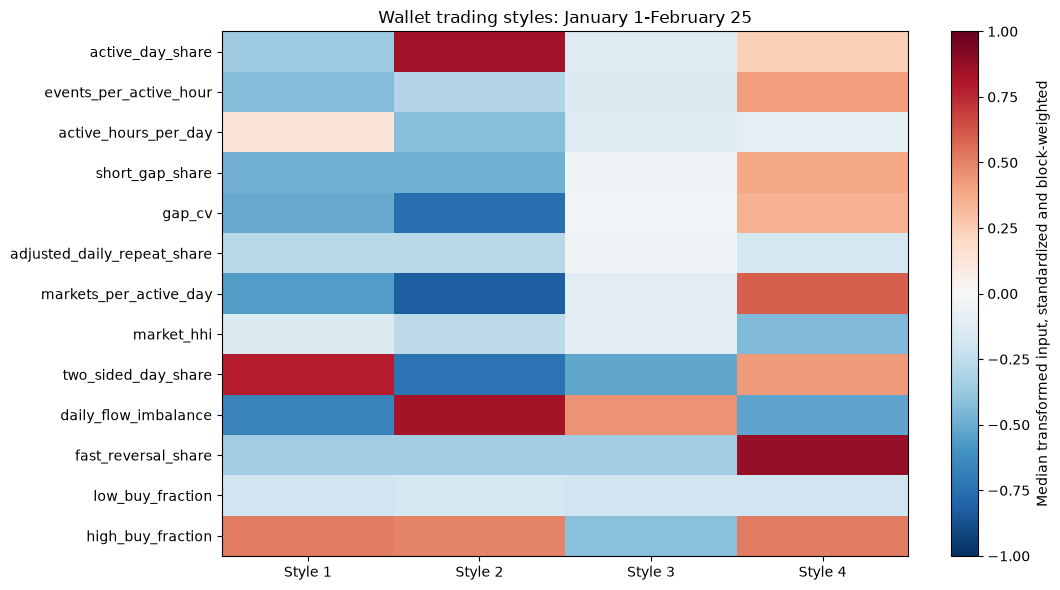

In [26]:
heatmap = pd.DataFrame(X_train, columns=cluster_features).assign(
    style=training_profiles["style"].to_numpy()
).groupby("style").median().T
fig, ax = plt.subplots(figsize=(11, 6))
limit = max(1, np.abs(heatmap.to_numpy()).max())
image = ax.imshow(heatmap, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(4), list(style_names))
ax.set_yticks(range(len(cluster_features)), cluster_features)
ax.set_title("Wallet trading styles: January 1-February 25")
fig.colorbar(image, ax=ax, label="Median transformed input, standardized and block-weighted")
plt.tight_layout()
plt.show()

### 4. Representative wallets

For each trading style, we select a representative wallet whose transformed features are closest to the group's median profile. We use only Window 1 to select these wallets. The plots then show their daily trading activity across all three windows, measured by the number of trading seconds per day. A value of zero means that no trades were recorded for that wallet on that day.

,style,wallet,active_days,n_events,adjusted_daily_repeat_share,median_active_day_dollars,whale_scale
0,Style 1,0x5893262059fb4ffc4e6eed329260e1d3c0768a1f,8,26,0.000,673.659,False
1,Style 2,0xb1dd3948aebe232f73f423f5df3c7bd991beecca,35,47,0.000,886.25,False
2,Style 3,0xa83d3a5015a79f5a43b859a7f929c82d559a60bb,11,36,0.040,10.025,False
3,Style 4,0x300da94c9c1d42275d3cbd0e7d8b76b407c8711b,25,188,0.037,99.936,False


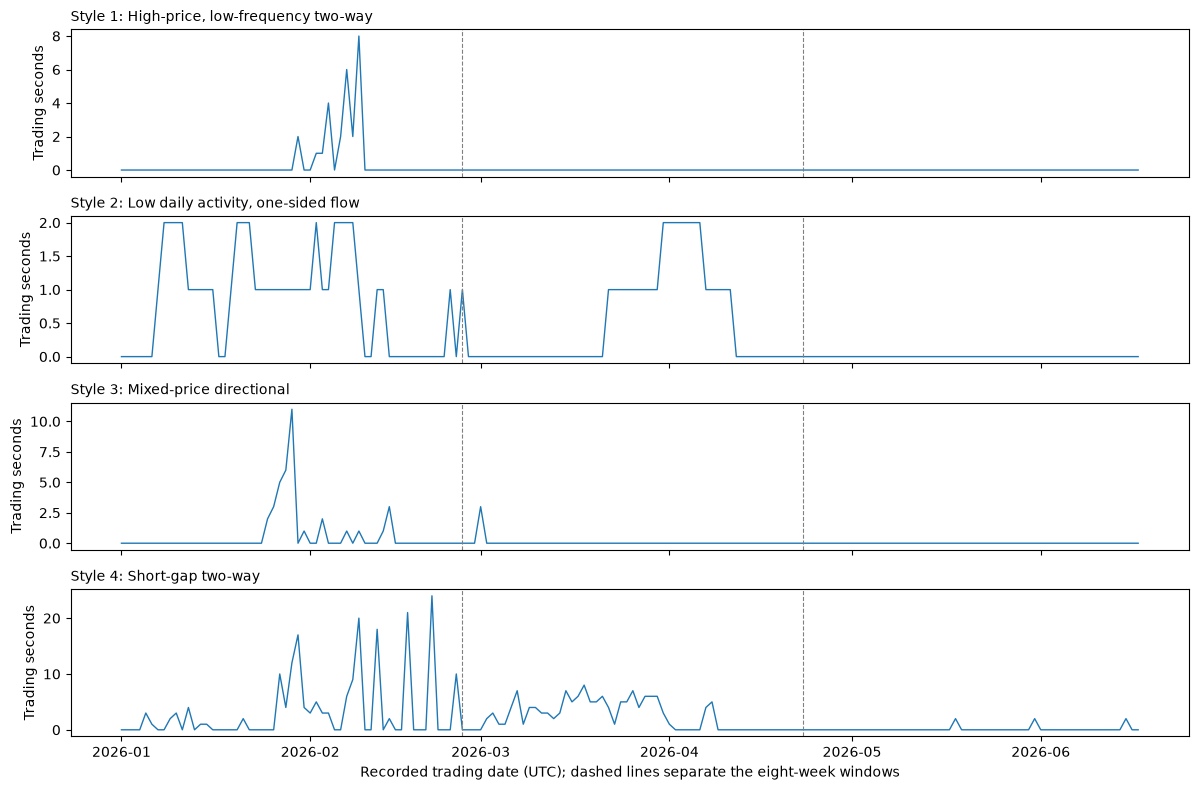

In [27]:
training_profiles = training_profiles.reset_index(drop=True)
example_positions = []
for style, group in training_profiles.groupby("style"):
    rows = group.index.to_numpy()
    center = np.median(X_train[rows], axis=0)
    typical = rows[np.argmin(np.mean(np.abs(X_train[rows] - center), axis=1))]
    example_positions.append(typical)
examples = training_profiles.iloc[example_positions][[
    "style", "wallet", "active_days", "n_events", "adjusted_daily_repeat_share",
    "median_active_day_dollars", "whale_scale",
]]
display(examples.reset_index(drop=True).round(3))

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, example in zip(axes, examples.itertuples(index=False)):
    activity = daily_summary.loc[daily_summary["wallet"].eq(example.wallet)].set_index("day")["n_events"]
    ax.plot(dates, activity.reindex(dates, fill_value=0), linewidth=1)
    for boundary in windows["start"].iloc[1:]:
        ax.axvline(pd.Timestamp(boundary, tz="UTC"), color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(f"{example.style}: {style_names[example.style]}", loc="left", fontsize=10)
    ax.set_ylabel("Trading seconds")
axes[-1].set_xlabel("Recorded trading date (UTC); dashed lines separate the eight-week windows")
plt.tight_layout()
plt.show()

## Styles Across Time

### 1. Follow every original wallet

Keep all eligible window-1 wallets in the cohort. Distinguish **profiled again**, **recorded but below the profile threshold**, and **no recorded fills**. No later records do not establish a platform exit. Same-style agreement conditions on wallets profiled again; chance agreement, kappa, and ARI describe label agreement rather than prediction accuracy.

In [28]:
baseline_profiles = training_profiles[["wallet", "style"]].rename(columns={"style": "baseline_style"})
wallet_profiles = profile_data[["wallet", "window", "style"]].copy()
cohort = pd.MultiIndex.from_product(
    [baseline_profiles["wallet"], [1, 2, 3]], names=["wallet", "window"]
).to_frame(index=False)
cohort = cohort.merge(baseline_profiles, on="wallet", how="left", validate="many_to_one")
cohort = cohort.merge(wallet_features[["wallet", "window", "n_fills"]], on=["wallet", "window"], how="left", validate="one_to_one")
cohort = cohort.merge(wallet_profiles, on=["wallet", "window"], how="left", validate="one_to_one")
cohort["status"] = "Recorded, ineligible"
cohort.loc[cohort["n_fills"].isna(), "status"] = "No recorded fills"
cohort.loc[cohort["style"].notna(), "status"] = "Profiled"

followup_rows = []
for window in [2, 3]:
    group = cohort.loc[cohort["window"].eq(window)]
    paired = group.loc[group["style"].notna()]
    labels = list(style_names)
    a = paired["baseline_style"].value_counts().reindex(labels, fill_value=0)
    b = paired["style"].value_counts().reindex(labels, fill_value=0)
    followup_rows.append({
        "window": window, "original_wallets": len(group), "profiled_again": len(paired),
        "profiled_again_pct": 100 * len(paired) / len(group),
        "recorded_ineligible": int(group["status"].eq("Recorded, ineligible").sum()),
        "no_recorded_fills": int(group["status"].eq("No recorded fills").sum()),
        "same_style_pct": 100 * paired["style"].eq(paired["baseline_style"]).mean(),
        "chance_same_pct": 100 * a.dot(b) / len(paired)**2,
        "kappa": cohen_kappa_score(paired["baseline_style"], paired["style"]),
        "ARI": adjusted_rand_score(paired["baseline_style"], paired["style"]),
    })
profile_followup = pd.DataFrame(followup_rows).set_index("window")
display(profile_followup[["original_wallets", "profiled_again", "profiled_again_pct",
                          "recorded_ineligible", "no_recorded_fills"]].round(2))
display(profile_followup[["same_style_pct", "chance_same_pct", "kappa", "ARI"]].round(4))

,original_wallets,profiled_again,profiled_again_pct,recorded_ineligible,no_recorded_fills
window,,,,,
2,20090,7979,39.72,5162,6949
3,20090,4820,23.99,7354,7916


,same_style_pct,chance_same_pct,kappa,ARI
window,,,,
2,75.4856,35.0848,0.6224,0.5885
3,84.8133,50.2256,0.6949,0.6160


### 2. Which groups persist, and where do the others go?

The table shows how often wallets that qualify for analysis again keep their original trading style. The heatmaps include `all original wallets in each style`, even those with too little trading activity to qualify again or no recorded trades. This allows us to compare how stable each trading style is among active wallets and what happens to the entire original group over time.

,window,original_style,original_wallets,profiled_again,same_style_pct
0,2,Style 1,3559,1582,97.60
1,2,Style 2,554,329,96.66
2,2,Style 3,11369,3890,96.09
3,2,Style 4,4608,2178,19.42
4,3,Style 1,3559,1562,83.55
5,3,Style 2,554,0,NaN
6,3,Style 3,11369,2829,98.34
7,3,Style 4,4608,429,0.23


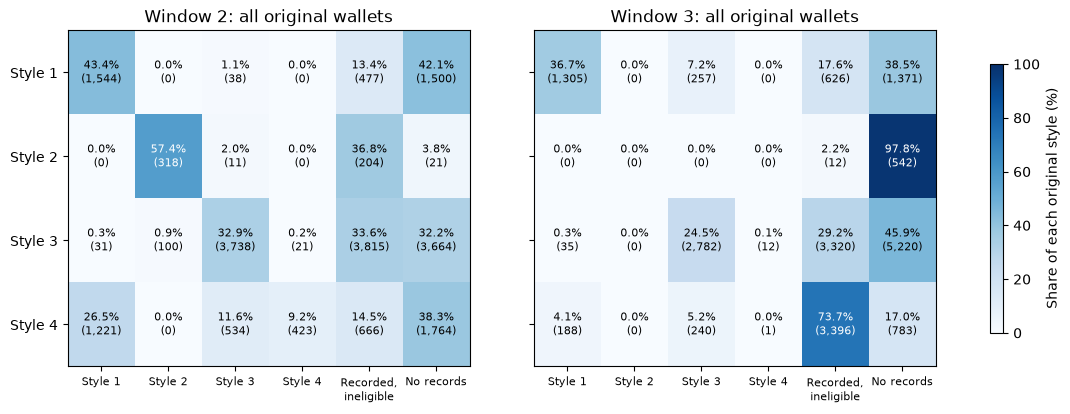

In [29]:
retention_rows = []
for (window, style), group in cohort.loc[cohort["window"].isin([2, 3])].groupby(["window", "baseline_style"]):
    paired = group.loc[group["style"].notna()]
    retention_rows.append({
        "window": window, "original_style": style, "original_wallets": len(group),
        "profiled_again": len(paired),
        "same_style_pct": 100 * paired["style"].eq(style).mean() if len(paired) else np.nan,
    })
style_retention = pd.DataFrame(retention_rows)
display(style_retention.round(2))

state_order = list(style_names) + ["Recorded, ineligible", "No recorded fills"]
cohort["later_state"] = cohort["style"].fillna(cohort["status"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, window in zip(axes, [2, 3]):
    group = cohort.loc[cohort["window"].eq(window)]
    counts = pd.crosstab(group["baseline_style"], group["later_state"]).reindex(
        index=list(style_names), columns=state_order, fill_value=0
    )
    values = counts.div(counts.sum(axis=1), axis=0) * 100
    image = ax.imshow(values, vmin=0, vmax=100, cmap="Blues", aspect="auto")
    for r in range(4):
        for c in range(6):
            ax.text(c, r, f"{values.iloc[r, c]:.1f}%\n({counts.iloc[r, c]:,})", ha="center", va="center",
                    fontsize=8, color="white" if values.iloc[r, c] > 55 else "black")
    ax.set(xticks=range(6), xticklabels=["Style 1", "Style 2", "Style 3", "Style 4", "Recorded,\nineligible", "No records"],
           yticks=range(4), yticklabels=list(style_names), title=f"Window {window}: all original wallets")
    ax.tick_params(axis="x", labelsize=8)
fig.subplots_adjust(bottom=0.18, wspace=0.16)
fig.colorbar(image, ax=axes.ravel().tolist(), label="Share of each original style (%)", shrink=0.8)
plt.show()

### 3. What changes within the short-gap two-way wallets?

Track the **same original Style 4 wallets eligible in all three windows**. Compare rhythm with purchase prices and two-sided daily flow. This retrospective panel conditions on later eligibility; it does not represent every original wallet. Changes can reflect behavior, market conditions, and recording coverage, so no causal mechanism is established.

The table contains wallet-level medians. A zero median does not mean every wallet has zero short gaps.

In [30]:
original_four = training_profiles.loc[training_profiles["style"].eq("Style 4"), "wallet"]
periods_observed = profile_data.loc[profile_data["wallet"].isin(original_four)].groupby("wallet")["window"].nunique()
fixed_panel_ids = periods_observed.index[periods_observed.eq(3)]
panel_features = ["active_days", "events_per_active_hour", "short_gap_share", "fast_reversal_share",
                  "two_sided_day_share", "high_buy_fraction", "median_active_day_dollars"]
fixed_panel = profile_data.loc[profile_data["wallet"].isin(fixed_panel_ids)]
fixed_panel_summary = fixed_panel.groupby("window")[panel_features].median().astype(float)
fixed_panel_summary.insert(0, "wallets", fixed_panel.groupby("window").size())
fixed_panel_summary.round(3)

,wallets,active_days,events_per_active_hour,short_gap_share,fast_reversal_share,two_sided_day_share,high_buy_fraction,median_active_day_dollars
window,,,,,,,,
1,414,17.0,2.936,0.576,0.228,0.571,1.0,113.935
2,414,43.0,1.183,0.000,0.000,0.581,1.0,147.259
3,414,19.0,1.418,0.000,0.006,0.587,1.0,145.504


## Settlement Comparison (Supplement)

### 1. Outcome sample and interpretation

Keep each original wallet's **window-1 label** when evaluating its later purchases. Use canonical `['Yes', 'No']` markets with a consistent terminal record before October 21, 2026. Other market labels remain in the profile study.

The recorded close time can fall back to a scheduled date; it is not a verified news timestamp. Exclude purchases at or after that time. Unmatched markets and wallets with no scored purchases are not assigned losses or zero returns.

Score **BUY entries hypothetically held to resolution**, ignoring actual SELLs: winning shares pay 1, losing shares pay 0. This benchmark describes entry outcomes before fees and rewards. It is not realized wallet PnL, full position accounting, or a measure of market-making profitability.

Style 2 has only 5 scored wallets in window 2 and 2 in window 3. Its return estimates have too little support for a substantive group comparison.

In [31]:
label_cutoff = pd.Timestamp("2026-10-21", tz="UTC")
settled = resolutions[["market_slug", "resolved_yes", "price_at_close", "resolved_at"]].merge(
    markets[["slug", "outcomes"]], left_on="market_slug", right_on="slug", how="inner", validate="one_to_one",
)
settled["resolved_at"] = pd.to_datetime(settled["resolved_at"], utc=True)
settled["price_at_close"] = pd.to_numeric(settled["price_at_close"])
canonical = settled["outcomes"].map(lambda labels: labels == ["Yes", "No"])
terminal = settled["price_at_close"].le(0.01) | settled["price_at_close"].ge(0.99)
consistent = settled["resolved_yes"].eq(settled["price_at_close"].gt(0.5))
settled = settled.loc[
    canonical & terminal & consistent
    & settled["resolved_at"].ge(pd.Timestamp(start_date, tz="UTC"))
    & settled["resolved_at"].lt(label_cutoff)
].copy()
settled["winning_outcome"] = np.where(settled["resolved_yes"], "Yes", "No")

buy_mask = (
    feature_trades["window"].isin([2, 3]) & feature_trades["side"].eq("BUY")
    & feature_trades["wallet"].isin(baseline_profiles["wallet"])
    & feature_trades["size"].gt(0) & feature_trades["dollars"].gt(0)
)
followup_buys = feature_trades.loc[
    buy_mask, ["wallet", "window", "market", "outcome", "time", "size", "dollars"]
].merge(baseline_profiles, on="wallet", how="inner", validate="many_to_one")
matched_buys = followup_buys.merge(
    settled[["market_slug", "resolved_at", "winning_outcome"]],
    left_on="market", right_on="market_slug", how="inner", validate="many_to_one",
)
scored_buys = matched_buys.loc[
    matched_buys["time"].lt(matched_buys["resolved_at"])
    & matched_buys["outcome"].isin(["Yes", "No"])
].copy()
scored_buys["won"] = scored_buys["outcome"].eq(scored_buys["winning_outcome"]).astype("int64")

In [32]:
settlement_coverage = followup_buys.groupby("window").agg(
    wallets_with_positive_buys=("wallet", "nunique"), buy_dollars=("dollars", "sum"),
)
settlement_coverage["scored_wallets"] = scored_buys.groupby("window")["wallet"].nunique()
settlement_coverage["scored_buy_dollars"] = scored_buys.groupby("window")["dollars"].sum()
settlement_coverage["scored_pct_of_original_wallets"] = 100 * settlement_coverage["scored_wallets"] / len(baseline_profiles)
settlement_coverage["scored_pct_of_cohort_buy_dollars"] = 100 * settlement_coverage["scored_buy_dollars"] / settlement_coverage["buy_dollars"]
settlement_coverage.round(2)

,wallets_with_positive_buys,buy_dollars,scored_wallets,scored_buy_dollars,scored_pct_of_original_wallets,scored_pct_of_cohort_buy_dollars
window,,,,,,
2,12214,127010636.33,8963,45084297.17,44.61,35.5
3,11454,171960025.62,8220,65248260.46,40.92,37.94


### 2. Hit rates and hypothetical returns

Aggregate once per wallet × market × outcome × window. This avoids counting split fills as independent wins. Buying both outcomes produces one entry for each side; hit rate alone does not measure skill.

Mean wallet hit rate and entry-price reference weight wallets equally. Pooled hypothetical ROI weights by BUY dollars; median wallet ROI describes a different, typical-wallet perspective.

In [33]:
entry_results = scored_buys.groupby(
    ["window", "baseline_style", "wallet", "market", "outcome"], as_index=False
).agg(
    buy_shares=("size", "sum"), buy_dollars=("dollars", "sum"), won=("won", "first"),
)
entry_results["avg_entry_price"] = entry_results["buy_dollars"] / entry_results["buy_shares"]
entry_results["hypothetical_profit"] = entry_results["buy_shares"] * entry_results["won"] - entry_results["buy_dollars"]

wallet_outcomes = entry_results.groupby(["window", "baseline_style", "wallet"], as_index=False).agg(
    settled_markets=("market", "nunique"), hit_rate=("won", "mean"),
    entry_price_reference=("avg_entry_price", "mean"),
    buy_dollars=("buy_dollars", "sum"), hypothetical_profit=("hypothetical_profit", "sum"),
)
wallet_outcomes["hypothetical_roi"] = wallet_outcomes["hypothetical_profit"] / wallet_outcomes["buy_dollars"]
performance = wallet_outcomes.groupby(["window", "baseline_style"]).agg(
    scored_wallets=("wallet", "size"), mean_wallet_hit_rate=("hit_rate", "mean"),
    mean_wallet_entry_price=("entry_price_reference", "mean"),
    median_wallet_roi=("hypothetical_roi", "median"),
    buy_dollars=("buy_dollars", "sum"), hypothetical_profit=("hypothetical_profit", "sum"),
)
performance["pooled_hypothetical_roi"] = performance["hypothetical_profit"] / performance["buy_dollars"]
baseline_counts = baseline_profiles["baseline_style"].value_counts()
performance["scored_pct_of_original_style"] = 100 * performance["scored_wallets"] / performance.index.get_level_values("baseline_style").map(baseline_counts)

outcome_summary = performance[[
    "scored_wallets", "scored_pct_of_original_style", "mean_wallet_entry_price", "mean_wallet_hit_rate",
    "median_wallet_roi", "pooled_hypothetical_roi",
]].copy()
for column in ["mean_wallet_entry_price", "mean_wallet_hit_rate", "median_wallet_roi", "pooled_hypothetical_roi"]:
    outcome_summary[column] = 100 * outcome_summary[column]
outcome_summary = outcome_summary.rename(columns={
    "scored_wallets": "Scored wallets", "scored_pct_of_original_style": "Original style covered (%)",
    "mean_wallet_entry_price": "Entry reference (%)", "mean_wallet_hit_rate": "Hit rate (%)",
    "median_wallet_roi": "Median wallet ROI (%)", "pooled_hypothetical_roi": "Pooled ROI (%)",
})
outcome_summary.round(2)

Scored wallets  Original style covered (%)  \
window baseline_style                                               
2      Style 1                   1769                        49.7   
       Style 2                      5                         0.9   
       Style 3                   4653                       40.93   
       Style 4                   2536                       55.03   
3      Style 1                   1775                       49.87   
       Style 2                      2                        0.36   
       Style 3                   3959                       34.82   
       Style 4                   2484                       53.91   

                       Entry reference (%)  Hit rate (%)  \
window baseline_style                                      
2      Style 1                       98.42         98.20   
       Style 2                       91.15         91.38   
       Style 3                       66.28         69.21   
       Style 4                       94.95         88.83   
3      Style 1                       98.37         98.59   
       Style 2                       71.59         75.00   
       Style 3                       62.14         63.80   
       Style 4                       95.02         94.86   

                       Median wallet ROI (%)  Pooled ROI (%)  
window baseline_style                                         
2      Style 1                          0.32           -0.04  
       Style 2                           0.5           -2.33  
       Style 3                           3.7           -3.35  
       Style 4                         -2.93           -6.76  
3      Style 1                          0.33            0.37  
       Style 2                          9.91           19.28  
       Style 3                           0.7            5.57  
       Style 4                          3.91           -0.53

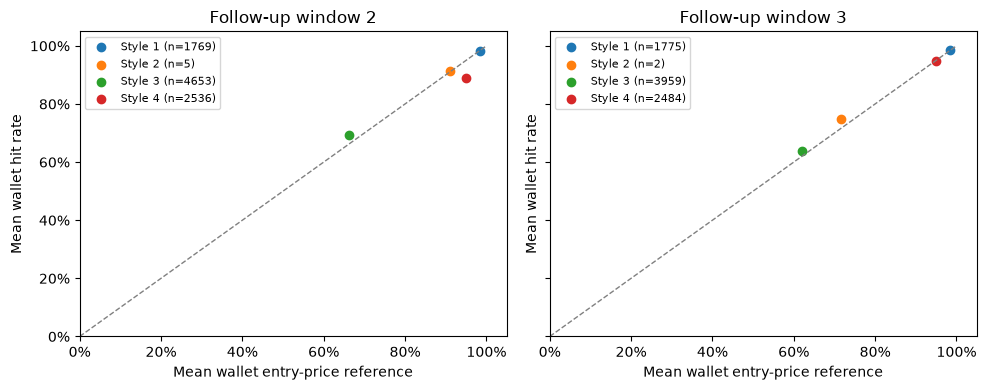

In [34]:
styles = list(style_names)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, window in zip(axes, [2, 3]):
    values = performance.loc[window].reindex(styles)
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
    for style, row in values.iterrows():
        ax.scatter(row["mean_wallet_entry_price"], row["mean_wallet_hit_rate"], label=f"{style} (n={int(row['scored_wallets'])})")
    ax.set(xlim=(0, 1.05), ylim=(0, 1.05), xlabel="Mean wallet entry-price reference", ylabel="Mean wallet hit rate", title=f"Follow-up window {window}")
    ax.legend(loc="upper left", fontsize=8)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

### 3. Pooled results versus the typical wallet

High hit rates can follow from buying high-priced contracts. Entry prices are descriptive probability references, not a guarantee of calibration. Positive pooled returns can also coexist with a negative median wallet return; neither figure should stand in for the other.

These are descriptive point estimates from the available settlement sample. They do not establish persistent profitability or distinguish skill from market selection and chance.

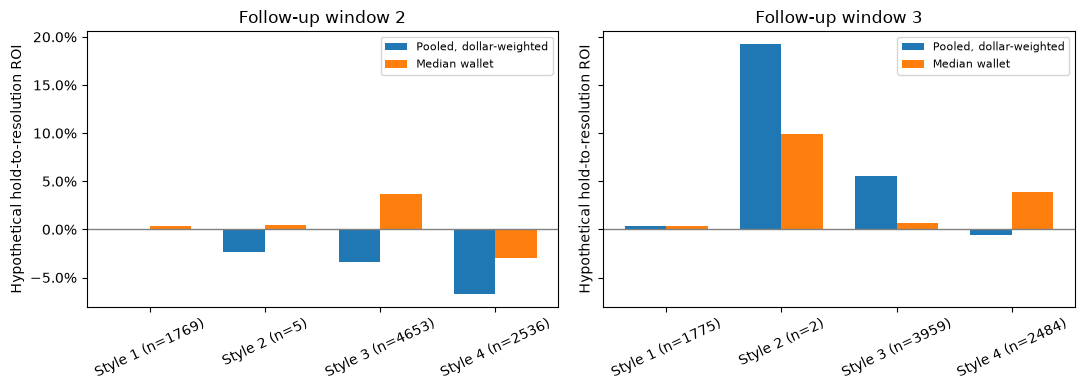

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
x = np.arange(len(styles))
for ax, window in zip(axes, [2, 3]):
    values = performance.loc[window].reindex(styles)
    ax.bar(x - 0.18, values["pooled_hypothetical_roi"], width=0.36, label="Pooled, dollar-weighted")
    ax.bar(x + 0.18, values["median_wallet_roi"], width=0.36, label="Median wallet")
    ax.axhline(0, color="grey", linewidth=1)
    ax.set_xticks(x, [f"{style} (n={int(values.loc[style, 'scored_wallets'])})" for style in styles], rotation=25)
    ax.set_title(f"Follow-up window {window}")
    ax.set_ylabel("Hypothetical hold-to-resolution ROI")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4. The last four weeks separately

The final four weeks contain 39.93 million fills, versus 3.97 million in the preceding four weeks. This observed coverage/composition change has an unresolved cause. Keep the original profiles and split only the later purchases below.

In [36]:
late_buys = scored_buys.loc[scored_buys["window"].eq(3)].copy()
late_buys["half"] = np.where(
    late_buys["time"].lt(pd.Timestamp("2026-05-21", tz="UTC")), "Apr 23-May 20", "May 21-Jun 17"
)
late_buys["hypothetical_profit"] = late_buys["size"] * late_buys["won"] - late_buys["dollars"]
late_comparison = late_buys.groupby(["baseline_style", "half"]).agg(
    buy_dollars=("dollars", "sum"), hypothetical_profit=("hypothetical_profit", "sum"),
)
late_comparison["pooled_roi_pct"] = 100 * late_comparison["hypothetical_profit"] / late_comparison["buy_dollars"]
late_comparison["pooled_roi_pct"].unstack("half").round(2)

half,Apr 23-May 20,May 21-Jun 17
baseline_style,,
Style 1,0.08,0.81
Style 2,19.28,<NA>
Style 3,1.29,7.23
Style 4,-4.07,4.72


## Findings

- **We identified four trading styles.** These include high-price, low-frequency two-way trading, low daily activity with one-sided flow, mixed-price directional trading, and short-gap two-way trading. The four groups contain 3,559, 554, 11,369, and 4,608 wallets in Window 1. Our model includes 9.09% of all recorded wallets in this window, which account for 65.37% of total fills. This means our findings mainly describe wallets with enough trading activity to measure their behavior.

- **Whale-scale activity appears across all four styles.** We define Whale-scale wallets as those with a median active-day turnover of at least $4,237.78, based on the top 1% of the Window 1 training sample. There are 201 qualifying wallets, with 86, 27, 83, and 5 wallets in Styles 1–4. This shows that trading style and trading volume describe different aspects of wallet behavior.

- **Trading style consistency depends on which wallets remain eligible for analysis.** Among wallets that qualify again, 75.49% keep their original style in Window 2, compared with 84.81% in Window 3. However, only 7,979 wallets (39.72%) qualify again in Window 2, and 4,820 (23.99%) in Window 3. The expected agreement by chance is 35.08% and 50.23%, while Cohen's kappa is 0.622 and 0.695. These results suggest that trading styles can remain consistent, but many original wallets become less active or have no recorded trades.

- **Some trading styles are more stable than others.** Among wallets that remain eligible, Style 3 shows high consistency, with 96.09% keeping the same style in Window 2 and 98.34% in Window 3. In contrast, Style 4 has much lower consistency, at 19.42% and 0.23%. Style 2 also shows a major decline in recorded activity. By Window 3, none of its original wallets qualify for clustering, and 542 out of 554 have no recorded trades. This shows that the overall consistency rate does not reflect the behavior of every trading style equally.

- **Some trading habits remain consistent even when trading frequency changes.** We follow the same 414 original Style 4 wallets that qualify for analysis in all three windows. Their median high-price `BUY` share stays at 100%, and their median two-sided trading share remains around 57–59%. However, their median short-gap share drops from 57.63% to 0%, while trading seconds per active trading hour change from 2.94 to 1.18 and then 1.42. This suggests that these wallets maintain some trading preferences while changing how frequently they trade. We cannot determine the exact cause of these changes from the available data.

The settlement analysis provides additional information about trading outcomes. However, Style 2 has only 5 scored wallets in Window 2 and 2 in Window 3, which is too small for a reliable comparison. Our hypothetical returns assume that all `BUY` positions are held until settlement and do not account for actual selling activity or complete wallet profits and losses. The large increase in recorded trades during the final four weeks also makes comparisons across time less certain.

Overall, our study identifies different trading styles and shows how wallet behavior changes over time. The results help us understand trading frequency, market preferences, trading direction, and trading volume. However, these patterns alone cannot tell us whether a wallet is controlled by a bot or an insider. Identifying those activities would require additional data and evidence.